<a href="https://colab.research.google.com/github/rhmau1/PCVK_26/blob/main/Modul7/Modul7-D2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pytesseract

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


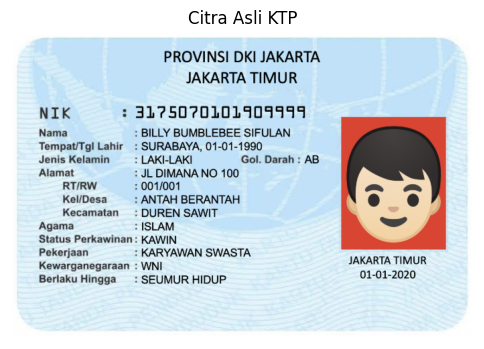

--- Hasil OCR citra berwarna ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31750701019099949
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir_: SURABAYA, 01-01-1990
Jenis Kelamin —_: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW 001/001

KellDesa__: ANTAH BERANTAH \ y

Kecamatan : DUREN SAWIT ,
Agama HISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI pret rees
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020



In [ ]:
filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
fijri = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
img = cv.imread(fijri)

img_rgb = cv.cvtColor(
    img,
    cv.COLOR_BGR2RGB
)


plt.figure(figsize=(6,4))
plt.imshow(img_rgb)
plt.title("Citra Asli KTP")
plt.axis('off')
plt.show()


# 2. Pembacaan Teks dengan PyTesseract
custom_config = r'--oem 3 --psm 6'
text_adaptive = pytesseract.image_to_string(img_rgb, config=custom_config)
print("--- Hasil OCR citra berwarna ---")
print(text_adaptive)

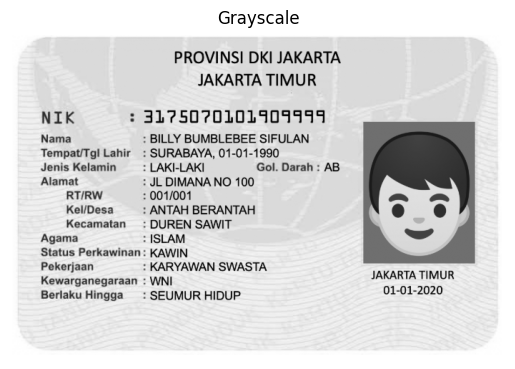

In [ ]:
gray = cv.cvtColor(
    img,
    cv.COLOR_BGR2GRAY
)


plt.imshow(gray,cmap='gray')
plt.title("Grayscale")
plt.axis('off')
plt.show()

Nilai Threshold Otsu : 150.0


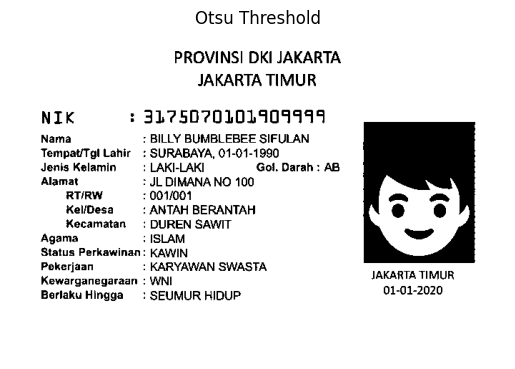

--- Hasil OCR otsu ---
PROVINS! DKI JAKARTA
JAKARTA TIMUR

NIK + 31750701019099949
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir_ : SURABAYA, 01-01-1990
denis Kelamin —: LAKI-LAKI Gol, Darah : AB
Alamat : JL DIMANA NO 100

RTRW 2 001/001

KevDesa —: ANTAH BERANTAH.

Kecamatan : DUREN SAWIT
Agama 7 ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga : SEUMUR HIDUP 01-01-2020



In [ ]:
otsu_threshold, otsu_img = cv.threshold(
    gray,
    0,
    255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)


print("Nilai Threshold Otsu :", otsu_threshold)


plt.imshow(
    otsu_img,
    cmap='gray'
)

plt.title(
    "Otsu Threshold"
)

plt.axis('off')
plt.show()


# 2. Pembacaan Teks dengan PyTesseract
custom_config = r'--oem 3 --psm 6'
text_adaptive = pytesseract.image_to_string(otsu_img, config=custom_config)
print("--- Hasil OCR otsu ---")
print(text_adaptive)

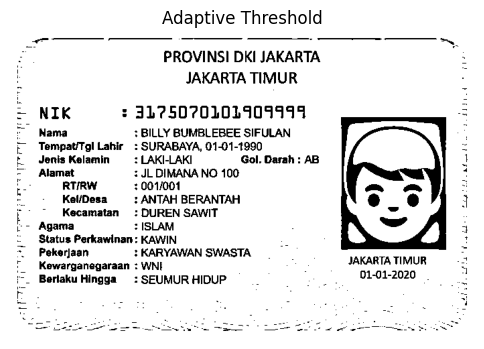

--- Hasil OCR Adaptive Thresholding ---
OS om |
f PROVINSI DKI JAKARTA 2
a JAKARTA TIMUR .
= NIK = 31750701019099949 S
= Nama : BILLY BUMBLEBEE SIFULAN
;- Tempat/Tgl Lahir : SURABAYA, 01-01-1990 =
t denis Kelamin —: LAKI-LAKI Gol. Darah : AB a
> Alamat JL DIMANA NO 100 :
t RTRW 001/001 2
2 Kel(Desa =: ANTAH BERANTAH. 3
[0 > Kecamatan : DUREN SAWIT
E- Agama ISLAM T\ /) a
= Status Perkawinan: KAWIN L 2
= Pekerjaan : KARYAWAN SWASTA =
© Kewarganegaraan : WNI JAKARTA mu Mu Z
©. BerlakuHingga = :SEUMURHIDUP . o <
E - . . : 3

“fos ianee bt hie ee



In [ ]:
# 1. Segmentasi menggunakan Adaptive Thresholding
adaptive_img = cv.adaptiveThreshold(
    gray,
    255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    55,
    15
)

# Menampilkan hasil Adaptive Thresholding
plt.figure(figsize=(6,4))
plt.imshow(adaptive_img, cmap='gray')
plt.title("Adaptive Threshold")
plt.axis('off')
plt.show()

# 2. Pembacaan Teks dengan PyTesseract
custom_config = r'--oem 3 --psm 6'
text_adaptive = pytesseract.image_to_string(adaptive_img, config=custom_config)
print("--- Hasil OCR Adaptive Thresholding ---")
print(text_adaptive)

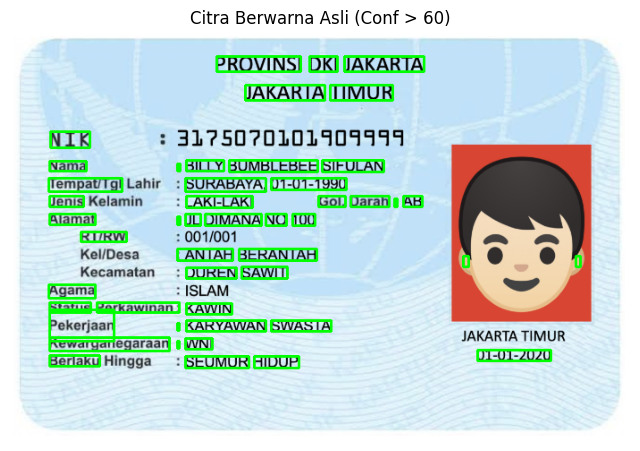

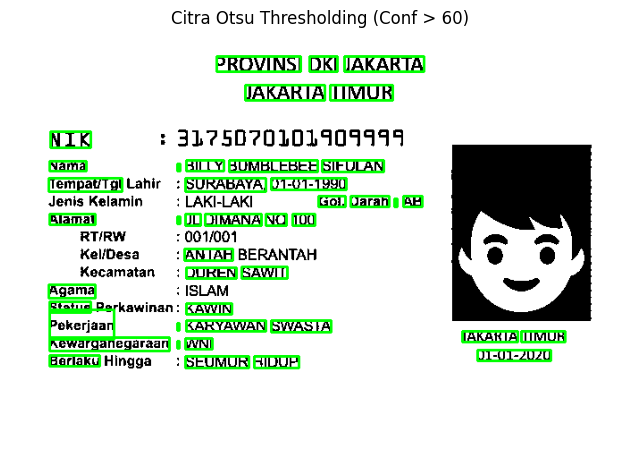

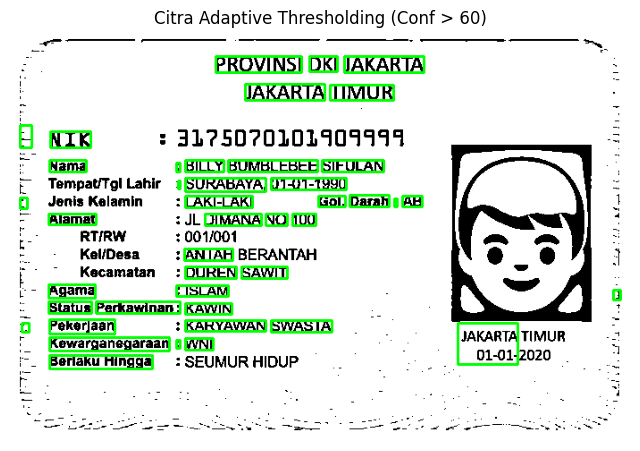

In [ ]:
def draw_ocr_boxes(image, title, conf_threshold=60):
    # Buat salinan citra agar citra asli tidak tertimpa
    img_copy = image.copy()
    if len(img_copy.shape) == 2:
        # Jika grayscale, ubah ke RGB agar bisa menggambar kotak hijau
        img_copy = cv.cvtColor(img_copy, cv.COLOR_GRAY2RGB)

    # Dapatkan data OCR berupa dictionary
    d = pytesseract.image_to_data(image, output_type=pytesseract.Output.DICT, config=r'--oem 3 --psm 6')
    n_boxes = len(d['level'])

    for i in range(n_boxes):
        # Ambil nilai confidence
        conf = int(d['conf'][i])
        if conf > conf_threshold:
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
            # Gambar kotak hijau (0, 255, 0) dengan ketebalan garis 2
            cv.rectangle(img_copy, (x, y), (x + w, y + h), (0, 255, 0), 2)

    plt.figure(figsize=(8, 6))
    plt.imshow(img_copy)
    plt.title(f"{title} (Conf > {conf_threshold})")
    plt.axis('off')
    plt.show()

# Memanggil fungsi untuk ketiga citra
draw_ocr_boxes(img_rgb, "Citra Berwarna Asli", conf_threshold=60)
draw_ocr_boxes(otsu_img, "Citra Otsu Thresholding", conf_threshold=60)
draw_ocr_boxes(adaptive_img, "Citra Adaptive Thresholding", conf_threshold=60)

In [ ]:
# 1. Menentukan 10 kata/angka acuan yang sebenarnya
reference_data = [
    ("PROVINSI", "PROVINSI", "PROVINS!", "PROVINSI"),
    ("JAKARTA", "JAKARTA", "JAKARTA", "JAKARTA"),
    ("31750701019099949", "31750701019099949", "31750701019099949", "31750701019099949"),
    ("BILLY", "BILLY", "BILLY", "BILLY"),
    ("SIFULAN", "SIFULAN", "SIFULAN", "SIFULAN"),
    ("SURABAYA", "SURABAYA", "SURABAYA", "SURABAYA"),
    ("01-01-1990", "01-01-1990", "01-01-1990", "01-01-1990"),
    ("LAKI-LAKI", "LAKI-LAKI", "LAKI-LAKI", "LAKI-LAKI"),
    ("ISLAM", "HISLAM", "ISLAM", "ISLAM"),
    ("SEUMUR", "SEUMUR", "SEUMUR", "SEUMUR")
]

# 2. Membuat DataFrame perbandingan
data_table = []
for idx, (real, color, otsu, adaptive) in enumerate(reference_data, 1):
    data_table.append({
        "No.": idx,
        "Teks Sebenarnya": real,
        "OCR Citra Berwarna": color,
        "OCR Otsu": otsu,
        "OCR Adaptive": adaptive
    })

df = pd.DataFrame(data_table)

# 3. Menghitung persentase kecocokan (mengabaikan case-sensitive dan spasi tambahan)
def calculate_accuracy(col_name):
    match_count = 0
    for real, col_val in zip(df["Teks Sebenarnya"], df[col_name]):
        if str(real).strip().lower() == str(col_val).strip().lower():
            match_count += 1
    return (match_count / len(df)) * 100

accuracy_color = calculate_accuracy("OCR Citra Berwarna")
accuracy_otsu = calculate_accuracy("OCR Otsu")
accuracy_adaptive = calculate_accuracy("OCR Adaptive")

# Tampilkan tabel
import IPython.display as display
print("=== TABEL PERBANDINGAN HASIL OCR ===")
display.display(df.style.hide(axis='index'))

print("\n=== RINGKASAN AKURASI KECOCOKAN METODE ===")
print(f"Akurasi OCR Citra Berwarna   : {accuracy_color:.1f}%")
print(f"Akurasi OCR Otsu Thresholding : {accuracy_otsu:.1f}%")
print(f"Akurasi OCR Adaptive Thresh   : {accuracy_adaptive:.1f}%")

=== TABEL PERBANDINGAN HASIL OCR ===


No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,PROVINSI,PROVINS!,PROVINSI
2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
3,31750701019099949,31750701019099949,31750701019099949,31750701019099949
4,BILLY,BILLY,BILLY,BILLY
5,SIFULAN,SIFULAN,SIFULAN,SIFULAN
6,SURABAYA,SURABAYA,SURABAYA,SURABAYA
7,01-01-1990,01-01-1990,01-01-1990,01-01-1990
8,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI
9,ISLAM,HISLAM,ISLAM,ISLAM
10,SEUMUR,SEUMUR,SEUMUR,SEUMUR



=== RINGKASAN AKURASI KECOCOKAN METODE ===
Akurasi OCR Citra Berwarna   : 90.0%
Akurasi OCR Otsu Thresholding : 90.0%
Akurasi OCR Adaptive Thresh   : 100.0%


In [ ]:
def get_average_confidence(image):
    d = pytesseract.image_to_data(image, output_type=pytesseract.Output.DICT, config=r'--oem 3 --psm 6')
    confidences = [int(c) for c in d['conf'] if int(c) > -1]
    return np.mean(confidences) if confidences else 0.0

# Fungsi untuk menghitung jumlah item terbaca tepat secara dinamis
def count_exact_matches(col_name):
    match_count = 0
    for real, col_val in zip(df["Teks Sebenarnya"], df[col_name]):
        if str(real).strip().lower() == str(col_val).strip().lower():
            match_count += 1
    return match_count

# Menghitung item terbaca tepat secara dinamis
matches_color = count_exact_matches("OCR Citra Berwarna")
matches_otsu = count_exact_matches("OCR Otsu")
matches_adaptive = count_exact_matches("OCR Adaptive")

total_items = len(df)

# Menghitung rata-rata confidence
conf_color = get_average_confidence(img_rgb)
conf_otsu = get_average_confidence(otsu_img)
conf_adaptive = get_average_confidence(adaptive_img)

# Membuat data untuk tabel ringkasan secara dinamis
summary_data_full = [
    {
        "Citra Masukan OCR": "Citra Berwarna Asli",
        "Item Terbaca Tepat": f"{matches_color} / {total_items}",
        "Kecocokan%": f"{(matches_color / total_items) * 100:.1f}%",
        "Rata-rata Confidence": f"{conf_color:.2f}%"
    },
    {
        "Citra Masukan OCR": "Citra Otsu Thresholding",
        "Item Terbaca Tepat": f"{matches_otsu} / {total_items}",
        "Kecocokan%": f"{(matches_otsu / total_items) * 100:.1f}%",
        "Rata-rata Confidence": f"{conf_otsu:.2f}%"
    },
    {
        "Citra Masukan OCR": "Citra Adaptive Thresholding",
        "Item Terbaca Tepat": f"{matches_adaptive} / {total_items}",
        "Kecocokan%": f"{(matches_adaptive / total_items) * 100:.1f}%",
        "Rata-rata Confidence": f"{conf_adaptive:.2f}%"
    }
]

df_summary_full = pd.DataFrame(summary_data_full)

print("=== TABEL RINGKASAN EVALUASI OCR ===")
display.display(df_summary_full.style.hide(axis='index'))

=== TABEL RINGKASAN EVALUASI OCR ===


Citra Masukan OCR,Item Terbaca Tepat,Kecocokan%,Rata-rata Confidence
Citra Berwarna Asli,9 / 10,90.0%,69.88%
Citra Otsu Thresholding,9 / 10,90.0%,66.46%
Citra Adaptive Thresholding,10 / 10,100.0%,48.76%


1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
Berdasarkan hasil evaluasi OCR, citra masukan yang menghasilkan pembacaan paling tepat adalah Citra Adaptive Thresholding. Hal ini dibuktikan dari tabel evaluasi yang menunjukkan bahwa Adaptive Thresholding berhasil membaca 10 dari 10 item dengan tingkat kecocokan sebesar 100%. Sementara itu, Citra Berwarna Asli dan Otsu Thresholding hanya mampu membaca 9 dari 10 item dengan tingkat kecocokan sebesar 90%. Hasil tersebut menunjukkan bahwa Adaptive Thresholding mampu menghasilkan pemisahan teks dan background yang lebih baik sehingga teks lebih mudah dikenali oleh OCR.
2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
Berdasarkan hasil perbandingan OCR, terdapat beberapa kesalahan pembacaan karakter. Kesalahan pertama terjadi pada teks "ISLAM", dimana hasil OCR pada citra berwarna terbaca menjadi "HISLAM" karena huruf I salah dikenali sebagai karakter H. Kesalahan kedua terjadi pada teks "PROVINSI" pada hasil OCR Otsu Thresholding yang terbaca menjadi "PROVINS!", dimana huruf I terbaca sebagai simbol tanda seru. Kesalahan tersebut terjadi karena beberapa karakter memiliki bentuk yang mirip sehingga OCR mengalami kesulitan dalam mengenali karakter secara tepat.
3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
Tidak selalu. Berdasarkan hasil percobaan, segmentasi dapat meningkatkan hasil OCR apabila metode yang digunakan mampu memperjelas perbedaan antara teks dan background. Pada penelitian ini, Adaptive Thresholding berhasil meningkatkan hasil pembacaan hingga 100%, sedangkan Otsu Thresholding masih menghasilkan tingkat kecocokan yang sama dengan citra asli yaitu 90%. Hal ini menunjukkan bahwa efektivitas segmentasi bergantung pada karakteristik citra dan metode yang digunakan.
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
Warna dan pola latar belakang dapat memengaruhi hasil pembacaan OCR karena sistem harus membedakan antara teks dengan area di sekitarnya. Pada citra KTP, terdapat pola garis dan warna background yang cukup kompleks sehingga dapat menyebabkan beberapa karakter sulit dikenali. Jika warna atau intensitas background mendekati warna teks, OCR dapat mengalami kesalahan pembacaan. Proses segmentasi seperti thresholding membantu mengurangi pengaruh background sehingga teks menjadi lebih mudah dikenali.
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
Tidak. Berdasarkan hasil percobaan, metode dengan rata-rata confidence tertinggi tidak selalu memiliki tingkat kecocokan tertinggi. Citra Berwarna Asli memiliki rata-rata confidence paling tinggi yaitu 69,88%, tetapi tingkat kecocokannya hanya 90%. Sedangkan Adaptive Thresholding memiliki rata-rata confidence lebih rendah yaitu 48,76%, tetapi menghasilkan kecocokan tertinggi yaitu 100%. Hal ini menunjukkan bahwa nilai confidence OCR tidak selalu menunjukkan tingkat akurasi sebenarnya, sehingga hasil OCR tetap perlu dibandingkan dengan teks asli untuk mengetahui metode yang paling baik.